# Confidence Calibration — Temperature Scaling (All Four Hi-Res Models)

**No training happens in this notebook.** The four deployed single-input hi-res models
(`models/v4_hires_control_gap/`, with DenseNet121 served from the high-sensitivity t=0.305 checkpoint)
are loaded exactly as the app loads them (`app.inference.load_models`). This notebook only learns one
scalar per model that rescales its logits.

**Why:** the frontend shows a *confidence level* next to every verdict, so a borderline call is
presented as "uncertain, review recommended" rather than as a bare "Malignant". A raw softmax output
is not a trustworthy confidence: modern CNNs are systematically mis-calibrated, usually
over-confident (Guo et al., 2017, *On Calibration of Modern Neural Networks*). A model that says "90%"
should be right about 90% of the time; without calibration there is no such guarantee.

**Method — post-hoc temperature scaling (Guo et al., 2017):**

$$\hat p_{\text{cal}} = \sigma\!\left(\frac{z}{T}\right), \qquad z = z_{\text{malignant}} - z_{\text{benign}}$$

* `T` is fit per model by minimizing negative log-likelihood on the **validation** split
  (the test split is never used for fitting).
* `T > 1` softens over-confident outputs; `T < 1` sharpens under-confident ones.
* Dividing by a positive scalar is **monotonic**: the ranking of cases, ROC-AUC, and every
  threshold decision are unchanged. The 0.305 sensitivity operating point from
  `sensitivity_threshold_adjustment.ipynb` stays valid; only the *reported probability* changes.

**Evaluation (test split, before vs. after):** Expected Calibration Error (ECE, 15 equal-width bins,
top-label confidence as in Guo et al.), Brier score, NLL, and reliability diagrams.

In [1]:
import json
import os
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

ROOT = os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, ROOT)
from app import inference as I     # the exact load path the deployed app uses
H = I.H

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
LOGITS_PATH = os.path.join(RESULTS_DIR, "calibration_logits.npz")
TEMPS_PATH = os.path.join(RESULTS_DIR, "calibration_temperatures.json")
N_BINS = 15

models, meta = I.load_models(verbose=True)
dfs = {s: pd.read_csv(os.path.join(H.DF_DIR, f"{s}_df_hires.csv")) for s in ("val", "test")}
for s, d in dfs.items():
    print(f"  {s:5s} n={len(d):4d}   malignant {d[H.LABEL_COL].apply(H.encode_label).mean():.4f}")

  loaded DenseNet121      t=0.305 [high_sensitivity]  hires_control_gap_a0.5_densenet121_high_sensitivity_t0.305.pth


  loaded ResNet-50        t=0.500  hires_control_gap_a0.5_resnet50.pth


  loaded EfficientNet-B2  t=0.500  hires_control_gap_a0.5_efficientnet_b2.pth


  loaded VGG-16           t=0.500  hires_control_gap_a0.5_vgg16.pth


  val   n= 317   malignant 0.4196
  test  n= 319   malignant 0.4326


## Collect logits

One deterministic pass (no augmentation, `eval()` mode) over the validation and test splits. We keep
the binary logit `z = z1 - z0`; since `softmax([z0, z1])[1] = sigmoid(z1 - z0)`, this is the only
quantity temperature scaling acts on. Logits are cached so re-running the analysis cells is instant.

In [2]:
@torch.no_grad()
def collect_logits(model, df, batch_size=H.BATCH_SIZE):
    dl = DataLoader(H.HiResDataset(df, train=False), batch_size=batch_size, shuffle=False,
                    num_workers=H.NUM_WORKERS, pin_memory=H.PIN_MEMORY)
    zs, ys = [], []
    for full, _mask, _tl, y in tqdm(dl, leave=False):
        logits = model(full.to(H.DEVICE)).float()
        zs.append((logits[:, 1] - logits[:, 0]).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(zs), np.concatenate(ys)


if os.path.exists(LOGITS_PATH):
    cached = np.load(LOGITS_PATH)
    Z = {(a, s): cached[f"{a}_{s}_z"] for a in I.ARCHS for s in dfs}
    Y = {s: cached[f"{s}_y"] for s in dfs}
    print(f"Loaded cached logits from {LOGITS_PATH}")
else:
    Z, Y = {}, {}
    for arch in I.ARCHS:
        for split, df in dfs.items():
            Z[arch, split], Y[split] = collect_logits(models[arch], df)
            print(f"  {arch:16s} {split:5s} n={len(Y[split])}")
    np.savez_compressed(LOGITS_PATH,
                        **{f"{a}_{s}_z": Z[a, s] for a in I.ARCHS for s in dfs},
                        **{f"{s}_y": Y[s] for s in dfs})
    print(f"Saved logits to {LOGITS_PATH}")

Loaded cached logits from results\calibration_logits.npz


In [3]:
# Sanity check: these must be the same test-set probabilities Experiment 1 reported (Table 4.2).
sigmoid = lambda x: 1.0 / (1.0 + np.exp(-x))
for arch in I.ARCHS:
    ref_path = os.path.join("..", "experiment_1_baseline", "results",
                            f"testprobs_hires_control_gap_a0.5_{arch}.npz")
    if not os.path.exists(ref_path):
        print(f"  {arch:16s} no reference file")
        continue
    ref = np.load(ref_path)
    diff = np.abs(sigmoid(Z[arch, "test"]) - ref["probs"]).max()
    same_labels = np.array_equal(ref["labels"], Y["test"])
    print(f"  {arch:16s} max |p - p_exp1| = {diff:.2e}   labels match: {same_labels}")

  densenet121      max |p - p_exp1| = 1.19e-07   labels match: True
  resnet50         max |p - p_exp1| = 1.19e-07   labels match: True
  efficientnet_b2  max |p - p_exp1| = 5.96e-08   labels match: True
  vgg16            max |p - p_exp1| = 1.19e-07   labels match: True


## Fit the temperature and evaluate

`T` is optimized in log-space (so it stays positive) with L-BFGS on the validation NLL.

* **ECE** — bin test predictions by top-label confidence `max(p, 1-p)`; ECE is the
  sample-weighted average gap between mean confidence and accuracy per bin. 0 = perfectly calibrated.
* **Brier score** — mean squared error of `p(malignant)` against the 0/1 label (lower is better).
* **NLL** — the log-loss the temperature is fit on (lower is better).
* **ROC-AUC / accuracy** — reported only to confirm they are unchanged by scaling.

In [4]:
def fit_temperature(z, y, max_iter=200):
    z_t = torch.as_tensor(z, dtype=torch.float64)
    y_t = torch.as_tensor(y, dtype=torch.float64)
    log_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=max_iter, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(z_t / log_t.exp(), y_t)
        loss.backward()
        return loss

    opt.step(closure)
    return float(log_t.detach().exp())


def ece(p, y, n_bins=N_BINS):
    # Top-label ECE (Guo et al., 2017): confidence = probability of the argmax class.
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(int) == y).astype(float)
    edges = np.linspace(0.5, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1]), 0, n_bins - 1)
    total = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            total += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return float(total)


def nll(p, y, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def scores(p, y):
    return {"ece": ece(p, y), "brier": float(np.mean((p - y) ** 2)), "nll": nll(p, y),
            "roc_auc": roc_auc_score(y, p), "accuracy": float(((p >= 0.5) == y).mean())}


temps, rows = {}, []
for arch in I.ARCHS:
    T = fit_temperature(Z[arch, "val"], Y["val"])
    temps[arch] = T
    y = Y["test"]
    before = scores(sigmoid(Z[arch, "test"]), y)
    after = scores(sigmoid(Z[arch, "test"] / T), y)
    rows.append({"architecture": arch, "model": H.ARCH_DISPLAY_NAMES[arch], "temperature": T,
                 **{f"{k}_before": v for k, v in before.items()},
                 **{f"{k}_after": v for k, v in after.items()}})

calib = pd.DataFrame(rows)
calib.to_csv(os.path.join(RESULTS_DIR, "calibration_metrics.csv"), index=False)
pd.set_option("display.width", 240)
calib[["model", "temperature", "ece_before", "ece_after", "brier_before", "brier_after",
       "nll_before", "nll_after", "roc_auc_before", "roc_auc_after"]].round(4)

,model,temperature,ece_before,ece_after,brier_before,brier_after,nll_before,nll_after,roc_auc_before,roc_auc_after
0,DenseNet121,1.1233,0.0586,0.0709,0.1596,0.1598,0.4748,0.4768,0.8390,0.8390
1,ResNet-50,1.0118,0.0826,0.0841,0.1820,0.1819,0.5305,0.5304,0.7939,0.7939
2,EfficientNet-B2,1.2299,0.0780,0.0515,0.1754,0.1740,0.5165,0.5134,0.8133,0.8133
3,VGG-16,1.1116,0.0919,0.0839,0.1663,0.1653,0.4842,0.4849,0.8328,0.8328


In [5]:
# The decision at the deployed threshold is untouched: same predictions before and after.
for arch in I.ARCHS:
    t = meta[arch]["threshold"]
    raw = sigmoid(Z[arch, "test"]) >= t
    t_cal = sigmoid(np.log(t / (1 - t)) / temps[arch])
    cal = sigmoid(Z[arch, "test"] / temps[arch]) >= t_cal
    print(f"  {H.ARCH_DISPLAY_NAMES[arch]:16s} T={temps[arch]:.3f}  threshold {t:.3f} raw "
          f"== {t_cal:.3f} calibrated   identical decisions: {np.array_equal(raw, cal)}")

  DenseNet121      T=1.123  threshold 0.305 raw == 0.324 calibrated   identical decisions: True
  ResNet-50        T=1.012  threshold 0.500 raw == 0.500 calibrated   identical decisions: True
  EfficientNet-B2  T=1.230  threshold 0.500 raw == 0.500 calibrated   identical decisions: True
  VGG-16           T=1.112  threshold 0.500 raw == 0.500 calibrated   identical decisions: True


In [6]:
# How much of the before/after ECE difference is noise? Paired bootstrap over the 319 test cases.
rng = np.random.default_rng(H.SEED)
N_BOOT = 2000
ci_rows = []
for arch in I.ARCHS:
    y = Y["test"]
    p0, p1 = sigmoid(Z[arch, "test"]), sigmoid(Z[arch, "test"] / temps[arch])
    b0, b1 = [], []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        b0.append(ece(p0[i], y[i])); b1.append(ece(p1[i], y[i]))
    b0, b1, d = np.array(b0), np.array(b1), np.array(b1) - np.array(b0)
    ci_rows.append({"model": H.ARCH_DISPLAY_NAMES[arch],
                    "ece_before_95ci": f"[{np.percentile(b0, 2.5):.3f}, {np.percentile(b0, 97.5):.3f}]",
                    "ece_after_95ci": f"[{np.percentile(b1, 2.5):.3f}, {np.percentile(b1, 97.5):.3f}]",
                    "delta_ece_95ci": f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"})
ci = pd.DataFrame(ci_rows)
ci.to_csv(os.path.join(RESULTS_DIR, "calibration_ece_bootstrap.csv"), index=False)
ci

,model,ece_before_95ci,ece_after_95ci,delta_ece_95ci
0,DenseNet121,"[0.058, 0.120]","[0.062, 0.131]","[-0.015, +0.030]"
1,ResNet-50,"[0.071, 0.147]","[0.074, 0.146]","[-0.015, +0.016]"
2,EfficientNet-B2,"[0.066, 0.135]","[0.056, 0.118]","[-0.044, +0.020]"
3,VGG-16,"[0.079, 0.149]","[0.075, 0.143]","[-0.036, +0.024]"


## Reliability diagrams

Each panel bins the test predictions by predicted `p(malignant)` and plots the observed fraction of
malignant cases per bin. A perfectly calibrated model lies on the diagonal; points below the diagonal
mean the model *over-states* malignancy risk, points above mean it under-states it. The bar
histogram underneath shows how many test cases fall in each bin.

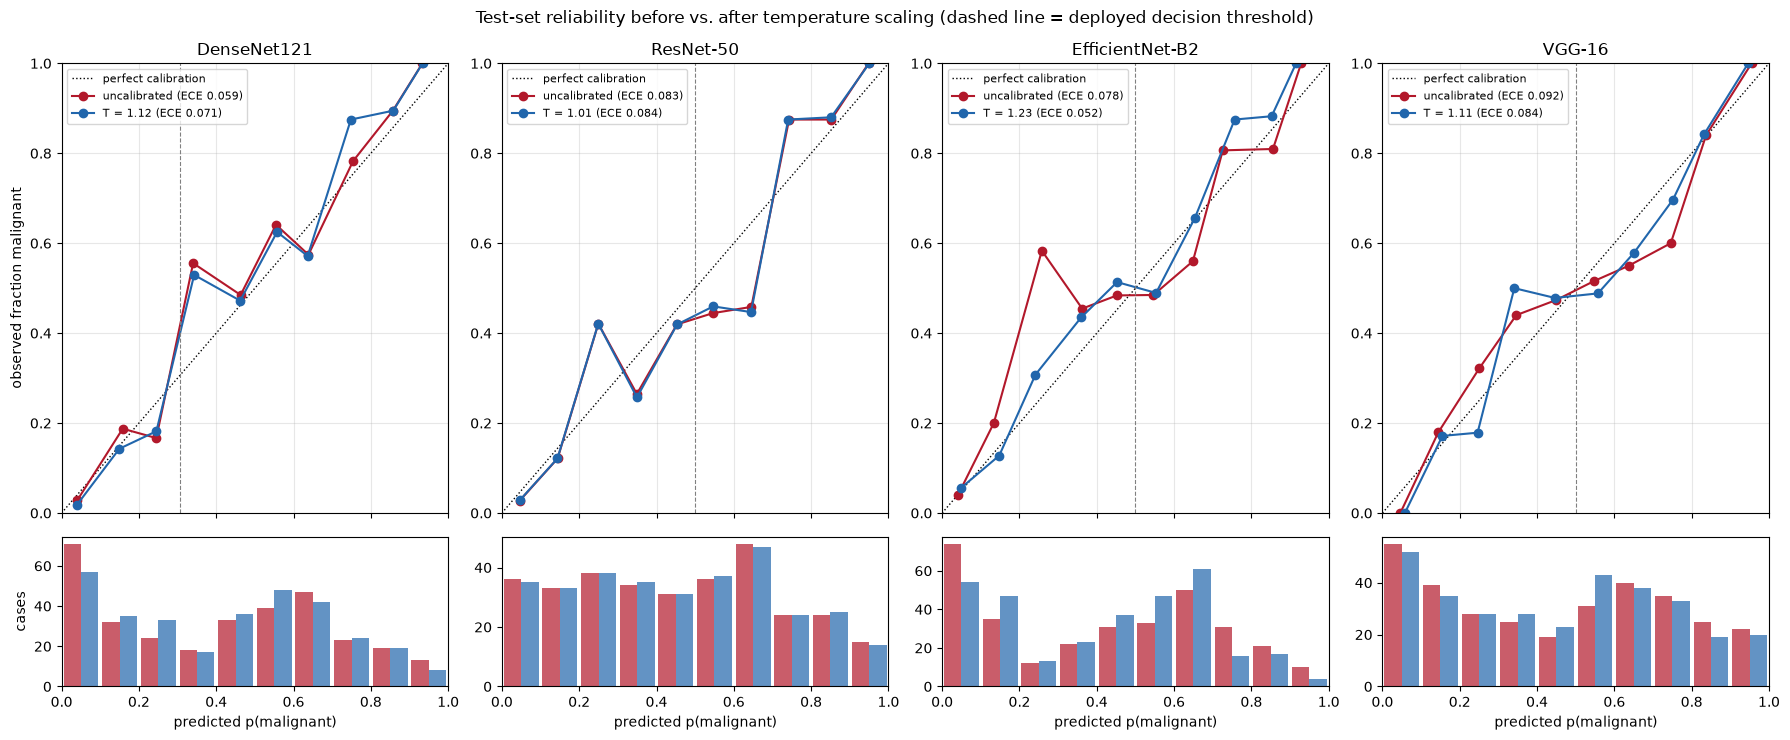

In [7]:
def reliability(p, y, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    mids, obs, counts = [], [], []
    for b in range(n_bins):
        m = idx == b
        counts.append(int(m.sum()))
        if m.any():
            mids.append(p[m].mean())
            obs.append(y[m].mean())
    return np.array(mids), np.array(obs), np.array(counts), edges


fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), gridspec_kw={"height_ratios": [3, 1]},
                         sharex=True)
for j, arch in enumerate(I.ARCHS):
    y = Y["test"]
    ax, hx = axes[0, j], axes[1, j]
    ax.plot([0, 1], [0, 1], ls=":", c="black", lw=1, label="perfect calibration")
    r = calib.set_index("architecture").loc[arch]
    for p, label, color, e in [
        (sigmoid(Z[arch, "test"]), "uncalibrated", "#b2182b", r["ece_before"]),
        (sigmoid(Z[arch, "test"] / temps[arch]), f"T = {temps[arch]:.2f}", "#2166ac", r["ece_after"]),
    ]:
        mids, obs, counts, edges = reliability(p, y)
        ax.plot(mids, obs, marker="o", color=color, label=f"{label} (ECE {e:.3f})")
        hx.bar(edges[:-1] + (0.05 if "T =" in label else 0.005), counts, width=0.045,
               align="edge", color=color, alpha=0.7)
    ax.axvline(meta[arch]["threshold"], color="grey", lw=0.8, ls="--")
    ax.set_title(H.ARCH_DISPLAY_NAMES[arch])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_ylabel("observed fraction malignant" if j == 0 else "")
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.3)
    hx.set_xlabel("predicted p(malignant)")
    hx.set_ylabel("cases" if j == 0 else "")
fig.suptitle("Test-set reliability before vs. after temperature scaling "
             "(dashed line = deployed decision threshold)")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "calibration_reliability.png"), dpi=150)
plt.show()

## Save the temperatures for the app

The fitted temperatures go into a sidecar JSON rather than being written back into the `.pth`
checkpoints, so the trained artifacts stay byte-identical to the ones evaluated in Experiments 1 and 2.
`app/inference.py` reads this file at start-up; when it is absent the app falls back to `T = 1`
(uncalibrated) and says so in its log.

In [8]:
payload = {
    arch: {
        "temperature": round(temps[arch], 6),
        "fit_split": "val",
        "n_fit": int(len(Y["val"])),
        "checkpoint": meta[arch]["checkpoint"],
        "test_ece_before": round(float(calib.set_index("architecture").loc[arch, "ece_before"]), 4),
        "test_ece_after": round(float(calib.set_index("architecture").loc[arch, "ece_after"]), 4),
    }
    for arch in I.ARCHS
}
with open(TEMPS_PATH, "w") as f:
    json.dump(payload, f, indent=2)
print(f"Saved {TEMPS_PATH}")
print(json.dumps(payload, indent=2))

Saved results\calibration_temperatures.json
{
  "densenet121": {
    "temperature": 1.123329,
    "fit_split": "val",
    "n_fit": 317,
    "checkpoint": "hires_control_gap_a0.5_densenet121_high_sensitivity_t0.305.pth",
    "test_ece_before": 0.0586,
    "test_ece_after": 0.0709
  },
  "resnet50": {
    "temperature": 1.011793,
    "fit_split": "val",
    "n_fit": 317,
    "checkpoint": "hires_control_gap_a0.5_resnet50.pth",
    "test_ece_before": 0.0826,
    "test_ece_after": 0.0841
  },
  "efficientnet_b2": {
    "temperature": 1.229915,
    "fit_split": "val",
    "n_fit": 317,
    "checkpoint": "hires_control_gap_a0.5_efficientnet_b2.pth",
    "test_ece_before": 0.078,
    "test_ece_after": 0.0515
  },
  "vgg16": {
    "temperature": 1.111623,
    "fit_split": "val",
    "n_fit": 317,
    "checkpoint": "hires_control_gap_a0.5_vgg16.pth",
    "test_ece_before": 0.0919,
    "test_ece_after": 0.0839
  }
}
